# Pothole-440 Preparation

**Part 1 of 2.** Companion notebook: `02_MiDaS31_Finetuning.ipynb`.

This notebook prepares the Pothole-440 RGB / pothole-mask / scanner-depth data.

## Scope
- Download the dataset and build group-separated train / validation / test splits.
- Estimate scanner-footprint masks and generate globally normalized targets.
- Build and verify the training manifest.
- Audit the scanner validity masks and correct the over-inclusive ones.
- Write the manifests and normalization limits consumed by Part 2.

**Important target limitation:** the depth PNGs are 8-bit scanner grayscale values. Their physical encoding and scale are not established here. Targets are therefore *relative scanner-intensity targets*, not metric depth.

**Outputs under `/kaggle/working`** (needed by Part 2):
`Pothole440_Grouped/`, `Pothole440_Targets_Global/` (including `training_manifest.csv` and `global_normalization.json`) and `Pothole440_Targets_Corrected/` (including `training_manifest_corrected.csv`).

No GPU is required. Internet is required for the `git clone`.

## 1. Download the dataset repository

In [1]:

import os
import subprocess
from pathlib import Path

REPO_URL = "https://github.com/Youngjincha/Pothole440.git"
REPO_DIR = Path("/kaggle/working/Pothole440")

if REPO_DIR.exists() and (REPO_DIR / ".git").exists():
    print("Repository already exists. Pulling latest changes...")
    subprocess.run(
        ["git", "-C", str(REPO_DIR), "pull"],
        check=True
    )
else:
    print("Cloning Pothole440 repository...")
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_DIR)],
        check=True
    )

print("\nRepository ready:", REPO_DIR)


Cloning Pothole440 repository...


Cloning into '/kaggle/working/Pothole440'...



Repository ready: /kaggle/working/Pothole440


Updating files: 100% (1332/1332), done.


## 2. Create group-separated dataset splits
Augmented/orientation variants derived from the same source pothole are assigned to one split to reduce group leakage. The grouping is based on filename suffix conventions.

In [2]:

import re
import shutil
import random
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit


# ============================================================
# CONFIGURATION
# ============================================================

SOURCE_ROOT = Path("/kaggle/working/Pothole440")

OUTPUT_ROOT = Path(
    "/kaggle/working/Pothole440_Grouped"
)

SPLITS = ["train", "val", "test"]

# Desired proportions by IMAGE COUNT
TARGET = {
    "train": 0.70,
    "val": 0.15,
    "test": 0.15
}

RANDOM_SEED = 42
N_SPLIT_TRIALS = 5000

# Set True to replace an existing generated output directory.
OVERWRITE_OUTPUT = True

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)


# ============================================================
# 1. SOURCE GROUP IDENTIFICATION
# ============================================================

def get_source_group(filename):

    """
    Remove augmentation and orientation suffixes.

    Examples:
    pothole_10_aug0                       -> pothole_10
    pothole_10_horizantal                 -> pothole_10
    pothole_10_vertical                   -> pothole_10
    pothole_10_horizantal_vertical_aug2   -> pothole_10
    """

    stem = Path(filename).stem.lower()

    suffix_pattern = re.compile(
        r"_(aug\d+|horizontal|horizantal|vertical)$",
        re.IGNORECASE
    )

    previous = None

    while previous != stem:
        previous = stem
        stem = suffix_pattern.sub("", stem)

    return stem


# ============================================================
# 2. COLLECT COMPLETE RGB-MASK-DEPTH TRIPLETS
# ============================================================

records = []
problems = []

for original_split in SPLITS:

    print(f"\nReading {original_split.upper()}...")

    rgb_dir = SOURCE_ROOT / original_split / "rgb"
    mask_dir = SOURCE_ROOT / original_split / "mask"
    depth_dir = SOURCE_ROOT / original_split / "depth"

    if not all(p.exists() for p in [
        rgb_dir, mask_dir, depth_dir
    ]):
        raise FileNotFoundError(
            f"Missing modality directory in {original_split}"
        )

    def index_files(folder):
        result = defaultdict(list)

        for path in folder.iterdir():
            if path.is_file():
                result[path.stem].append(path)

        return result

    rgb_files = index_files(rgb_dir)
    mask_files = index_files(mask_dir)
    depth_files = index_files(depth_dir)

    for stem, rgb_paths in rgb_files.items():

        if len(rgb_paths) != 1:
            problems.append(
                f"Multiple RGB files for {stem} in {original_split}"
            )
            continue

        if len(mask_files.get(stem, [])) != 1:
            problems.append(
                f"Missing or duplicate mask for {stem} in {original_split}"
            )
            continue

        if len(depth_files.get(stem, [])) != 1:
            problems.append(
                f"Missing or duplicate depth for {stem} in {original_split}"
            )
            continue

        rgb_path = rgb_paths[0]
        mask_path = mask_files[stem][0]
        depth_path = depth_files[stem][0]

        group = get_source_group(rgb_path.name)

        records.append({
            "filename": rgb_path.name,
            "stem": stem,
            "source_group": group,
            "original_split": original_split,
            "rgb_path": str(rgb_path),
            "mask_path": str(mask_path),
            "depth_path": str(depth_path)
        })


if problems:

    print("\nDATASET PROBLEMS:")
    for problem in problems:
        print(problem)

    raise RuntimeError(
        "Resolve missing or duplicate files before rebuilding."
    )


df = pd.DataFrame(records)

print("\n" + "=" * 65)
print("SOURCE DATASET")
print("=" * 65)

print("Complete triplets:", len(df))
print("Unique source groups:", df["source_group"].nunique())

print("\nOriginal split counts:")
print(df["original_split"].value_counts())


# ============================================================
# 3. INSPECT GROUP SIZES
# ============================================================

group_sizes = (
    df.groupby("source_group")
    .size()
    .sort_values(ascending=False)
)

print("\nLargest source groups:")
print(group_sizes.head(15).to_string())

print("\nGroup size statistics:")
print(group_sizes.describe())


# ============================================================
# 4. GENERATE GROUP-INDEPENDENT SPLITS
# ============================================================

unique_groups = np.array(
    df["source_group"].unique()
)

total_images = len(df)

target_counts = {
    split: TARGET[split] * total_images
    for split in SPLITS
}

print("\nTarget image counts:")
print(target_counts)


# Search for a split with approximately desired image counts.
# GroupShuffleSplit keeps each source group entirely together.

best_assignment = None
best_score = float("inf")
best_counts = None

for seed in range(N_SPLIT_TRIALS):

    # First separate testing groups.
    splitter_test = GroupShuffleSplit(
        n_splits=1,
        test_size=0.15,
        random_state=seed
    )

    all_indices = np.arange(len(unique_groups))

    remaining_idx, test_idx = next(
        splitter_test.split(
            all_indices,
            groups=unique_groups
        )
    )

    remaining_groups = unique_groups[remaining_idx]
    test_groups = set(unique_groups[test_idx])

    # Separate validation groups from remaining groups.
    splitter_val = GroupShuffleSplit(
        n_splits=1,
        test_size=0.1764705882,
        random_state=seed + 100000
    )

    remain_indices = np.arange(len(remaining_groups))

    train_local_idx, val_local_idx = next(
        splitter_val.split(
            remain_indices,
            groups=remaining_groups
        )
    )

    train_groups = set(
        remaining_groups[train_local_idx]
    )

    val_groups = set(
        remaining_groups[val_local_idx]
    )

    assignment = {
        "train": train_groups,
        "val": val_groups,
        "test": test_groups
    }

    counts = {
        split: int(
            df["source_group"].isin(assignment[split]).sum()
        )
        for split in SPLITS
    }

    # Squared normalized error against target image counts.
    score = sum(
        ((counts[s] - target_counts[s]) / total_images) ** 2
        for s in SPLITS
    )

    if score < best_score:
        best_score = score
        best_assignment = assignment
        best_counts = counts


if best_assignment is None:
    raise RuntimeError("Could not generate grouped splits.")


print("\nBest split found:")
print("Score:", best_score)
print("Image counts:", best_counts)


# ============================================================
# 5. ASSIGN NEW SPLITS
# ============================================================

group_to_split = {}

for split, groups in best_assignment.items():
    for group in groups:
        group_to_split[group] = split

df["new_split"] = df["source_group"].map(group_to_split)

if df["new_split"].isna().any():
    raise RuntimeError("Some source groups were not assigned.")


# ============================================================
# 6. VERIFY NO GROUP LEAKAGE
# ============================================================

group_sets = {
    split: set(
        df.loc[df["new_split"] == split, "source_group"]
    )
    for split in SPLITS
}

for i, split_a in enumerate(SPLITS):
    for split_b in SPLITS[i+1:]:

        overlap = group_sets[split_a] & group_sets[split_b]

        print(
            f"{split_a} vs {split_b} overlap:",
            len(overlap)
        )

        if overlap:
            raise RuntimeError(
                f"Group leakage detected between {split_a} and {split_b}"
            )


# ============================================================
# 7. PREPARE OUTPUT DIRECTORY
# ============================================================

if OUTPUT_ROOT.exists():

    if not OVERWRITE_OUTPUT:
        raise FileExistsError(
            f"{OUTPUT_ROOT} already exists. "
            "Set OVERWRITE_OUTPUT=True to replace it."
        )

    shutil.rmtree(OUTPUT_ROOT)


for split in SPLITS:
    for modality in ["rgb", "mask", "depth"]:
        (OUTPUT_ROOT / split / modality).mkdir(
            parents=True,
            exist_ok=True
        )


# ============================================================
# 8. COPY RGB, MASK AND DEPTH TOGETHER
# ============================================================

print("\nCopying files...")

copy_records = []

for _, row in df.iterrows():

    split = row["new_split"]

    # Prefix original split to avoid filename collisions.
    destination_name = (
        f"{row['original_split']}__{row['filename']}"
    )

    rgb_dest = OUTPUT_ROOT / split / "rgb" / destination_name
    mask_dest = OUTPUT_ROOT / split / "mask" / destination_name
    depth_dest = OUTPUT_ROOT / split / "depth" / destination_name

    shutil.copy2(row["rgb_path"], rgb_dest)
    shutil.copy2(row["mask_path"], mask_dest)
    shutil.copy2(row["depth_path"], depth_dest)

    copy_records.append({
        **row.to_dict(),
        "output_filename": destination_name,
        "output_rgb": str(rgb_dest),
        "output_mask": str(mask_dest),
        "output_depth": str(depth_dest)
    })


manifest = pd.DataFrame(copy_records)


# ============================================================
# 9. SAVE MANIFEST AND SUMMARY
# ============================================================

manifest_path = OUTPUT_ROOT / "dataset_manifest.csv"

manifest.to_csv(manifest_path, index=False)

summary = (
    manifest.groupby("new_split")
    .agg(
        image_count=("filename", "count"),
        unique_source_groups=("source_group", "nunique")
    )
    .reindex(SPLITS)
)

summary["actual_percentage"] = (
    summary["image_count"] / len(manifest) * 100
)

summary_path = OUTPUT_ROOT / "split_summary.csv"
summary.to_csv(summary_path)


# ============================================================
# 10. FINAL FILE VERIFICATION
# ============================================================

verification = []

for split in SPLITS:

    counts = {}

    for modality in ["rgb", "mask", "depth"]:

        folder = OUTPUT_ROOT / split / modality

        counts[modality] = len([
            p for p in folder.iterdir()
            if p.is_file()
        ])

    verification.append({
        "split": split,
        **counts,
        "all_equal": (
            counts["rgb"] ==
            counts["mask"] ==
            counts["depth"]
        )
    })


verification_df = pd.DataFrame(verification)

verification_df.to_csv(
    OUTPUT_ROOT / "file_verification.csv",
    index=False
)


# ============================================================
# FINAL REPORT
# ============================================================

print("\n" + "=" * 65)
print("GROUPED DATASET REBUILD COMPLETE")
print("=" * 65)

print("\nNEW SPLIT SUMMARY:")
print(summary.round(2))

print("\nFILE VERIFICATION:")
print(verification_df.to_string(index=False))

print("\nGROUP OVERLAP:")
for i, a in enumerate(SPLITS):
    for b in SPLITS[i+1:]:
        print(
            f"{a} / {b}:",
            len(group_sets[a] & group_sets[b])
        )

print("\nOutput directory:")
print(OUTPUT_ROOT)

print("\nGenerated reports:")
print(manifest_path)
print(summary_path)
print(OUTPUT_ROOT / "file_verification.csv")



Reading TRAIN...

Reading VAL...

Reading TEST...

SOURCE DATASET
Complete triplets: 440
Unique source groups: 98

Original split counts:
original_split
train    350
val       50
test      40
Name: count, dtype: int64

Largest source groups:
source_group
2022_05_22_pothole_10    8
2022_05_22_pothole_11    8
2022_05_22_pothole_12    8
2022_05_22_pothole_13    8
2022_05_22_pothole_14    8
2022_05_22_pothole_15    8
2022_05_22_pothole_16    8
2022_05_22_pothole_17    8
2022_05_22_pothole_18    8
2022_05_22_pothole_19    8
2022_05_22_pothole_20    8
2022_05_22_pothole_21    8
2022_05_22_pothole_22    8
2022_05_22_pothole_23    6
2022_05_22_pothole_24    4

Group size statistics:
count    98.000000
mean      4.489796
std       1.444827
min       1.000000
25%       4.000000
50%       4.000000
75%       4.000000
max       8.000000
dtype: float64

Target image counts:
{'train': 308.0, 'val': 66.0, 'test': 66.0}

Best split found:
Score: 0.0
Image counts: {'train': 308, 'val': 66, 'test': 66}


## 3. Inspect representative RGB, mask and scanner-depth triplets

train: 308 complete triplets
val: 66 complete triplets
test: 66 complete triplets
Selected: train__2022_05_22_pothole_14_horizantal_vertical_aug18.png
Selected: test__2022_06_03_pothole_28_horizantal_vertical.png
Selected: train__2022_06_01_pothole_24_vertical.png


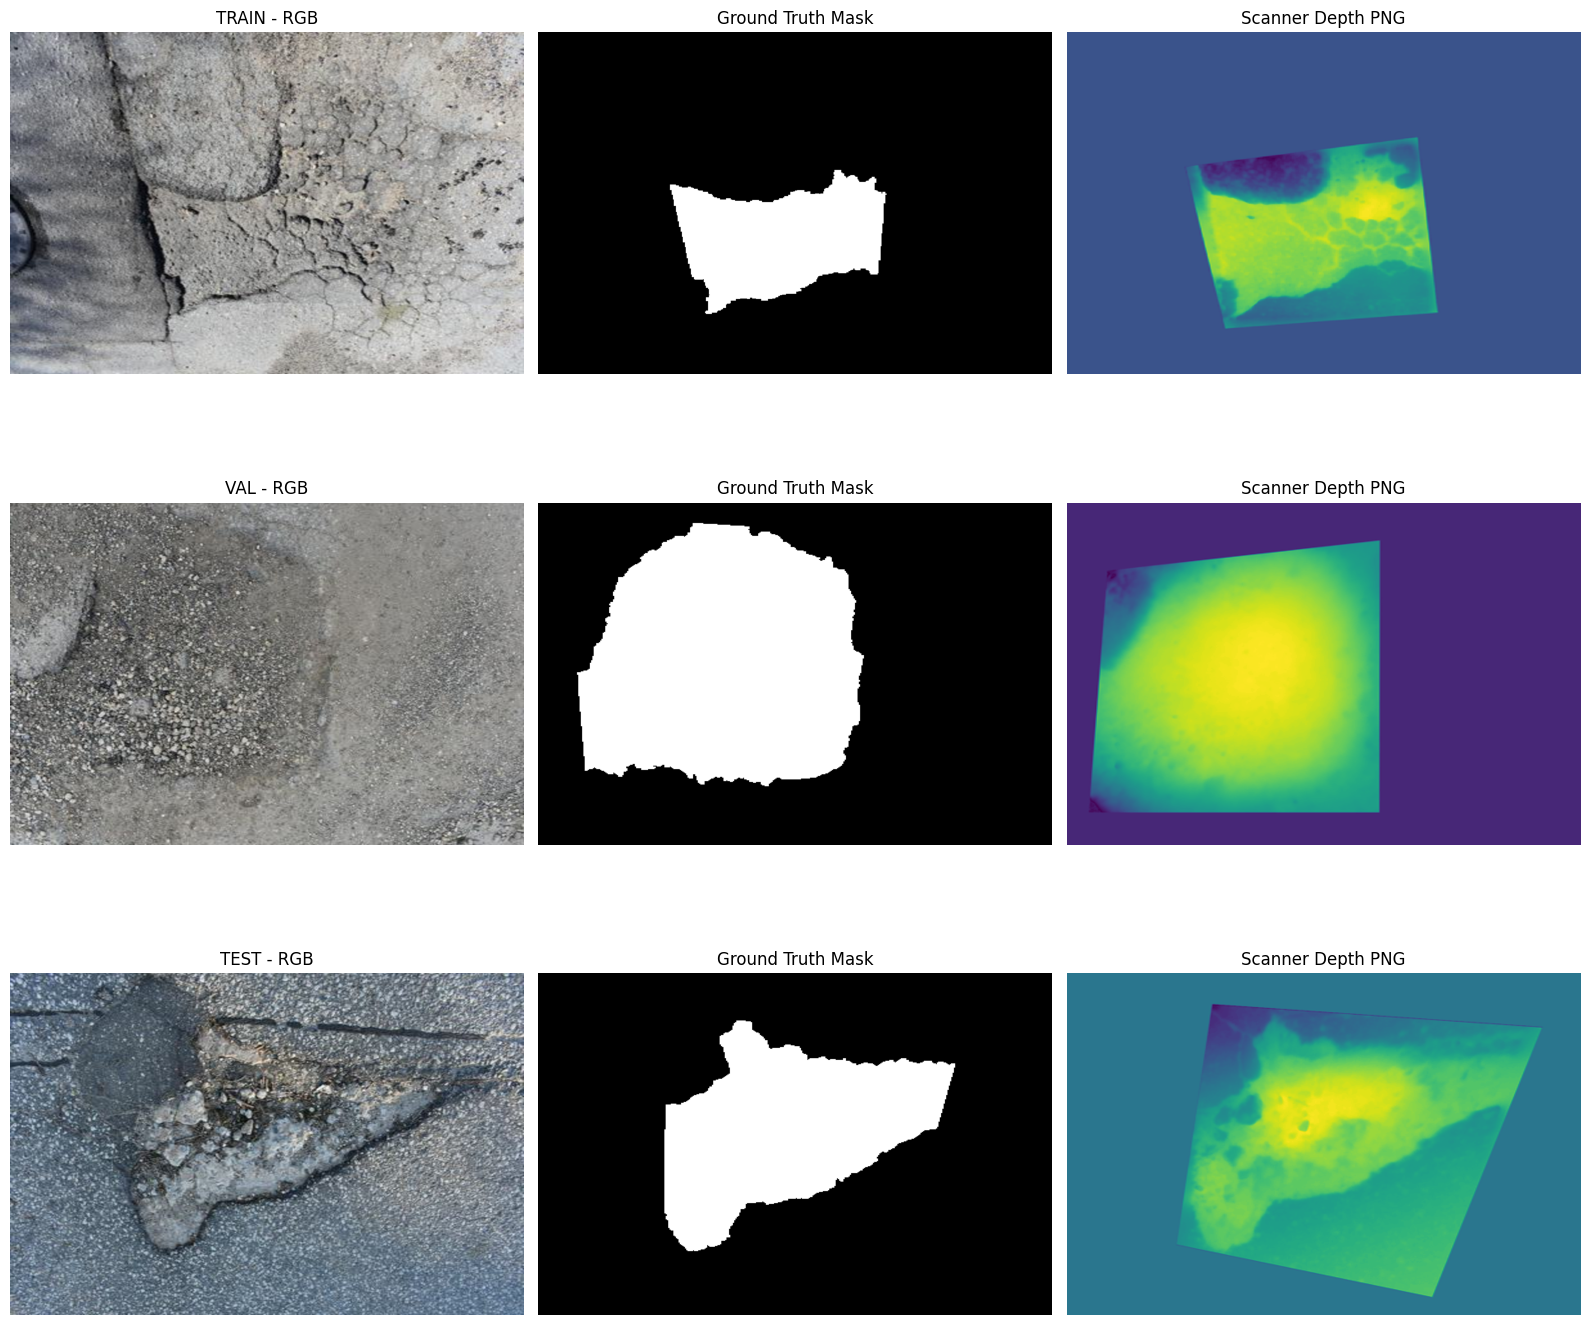

In [3]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import random

ROOT = Path("/kaggle/working/Pothole440_Grouped")
random.seed(42)

samples = []

for split in ["train", "val", "test"]:
    rgb_dir = ROOT / split / "rgb"
    mask_dir = ROOT / split / "mask"
    depth_dir = ROOT / split / "depth"

    candidates = sorted(
        p.name for p in rgb_dir.glob("*.png")
        if (mask_dir / p.name).exists()
        and (depth_dir / p.name).exists()
    )

    print(f"{split}: {len(candidates)} complete triplets")

    if candidates:
        samples.append((split, random.choice(candidates)))

fig, axes = plt.subplots(
    len(samples), 3,
    figsize=(16, 5 * len(samples)),
    squeeze=False
)

for i, (split, filename) in enumerate(samples):

    rgb = cv2.imread(str(ROOT / split / "rgb" / filename))
    mask = cv2.imread(str(ROOT / split / "mask" / filename),
                      cv2.IMREAD_GRAYSCALE)
    depth = cv2.imread(str(ROOT / split / "depth" / filename),
                       cv2.IMREAD_GRAYSCALE)

    rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

    axes[i, 0].imshow(rgb)
    axes[i, 0].set_title(f"{split.upper()} - RGB")

    axes[i, 1].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title("Ground Truth Mask")

    axes[i, 2].imshow(depth, cmap="viridis")
    axes[i, 2].set_title("Scanner Depth PNG")

    for ax in axes[i]:
        ax.axis("off")

    print(f"Selected: {filename}")

plt.tight_layout()
plt.show()

## 4. Estimate scanner footprints and create initial validity masks
The footprint is estimated heuristically from the dominant border intensity, morphological closing and the largest connected component. This is a candidate scanner-support mask, not independently verified ground truth.

In [4]:

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.auto import tqdm

ROOT = Path("/kaggle/working/Pothole440_Grouped")
OUT = Path("/kaggle/working/Pothole440_Targets")

SPLITS = ["train", "val", "test"]

for split in SPLITS:
    (OUT / split / "targets").mkdir(parents=True, exist_ok=True)
    (OUT / split / "valid_masks").mkdir(parents=True, exist_ok=True)


def estimate_scanner_mask(depth):
    """
    Estimate the scanner footprint from the dominant border intensity.
    Returns a binary mask and the estimated background intensity.
    """
    border = np.concatenate([
        depth[0, :],
        depth[-1, :],
        depth[:, 0],
        depth[:, -1]
    ])

    background = int(np.bincount(border).argmax())

    candidate = (
        np.abs(depth.astype(np.int16) - background) > 3
    ).astype(np.uint8)

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (5, 5)
    )

    candidate = cv2.morphologyEx(
        candidate, cv2.MORPH_CLOSE, kernel
    )

    n, labels, stats, _ = cv2.connectedComponentsWithStats(
        candidate, connectivity=8
    )

    if n <= 1:
        return None, background

    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    scanner_mask = (labels == largest).astype(np.uint8)

    return scanner_mask, background


records = []

for split in SPLITS:

    rgb_dir = ROOT / split / "rgb"
    depth_dir = ROOT / split / "depth"
    mask_dir = ROOT / split / "mask"

    filenames = sorted(p.name for p in rgb_dir.glob("*.png"))

    print(f"\nProcessing {split}: {len(filenames)} images")

    for filename in tqdm(filenames):

        depth_path = depth_dir / filename
        mask_path = mask_dir / filename

        depth = cv2.imread(
            str(depth_path), cv2.IMREAD_GRAYSCALE
        )
        pothole_mask = cv2.imread(
            str(mask_path), cv2.IMREAD_GRAYSCALE
        )

        if depth is None or pothole_mask is None:
            print("Skipping unreadable:", filename)
            continue

        if depth.shape != pothole_mask.shape:
            print("Skipping dimension mismatch:", filename)
            continue

        scanner_mask, background = estimate_scanner_mask(depth)

        if scanner_mask is None:
            print("Skipping scanner detection failure:", filename)
            continue

        valid = scanner_mask > 0
        pothole = pothole_mask > 127

        values = depth[valid]

        if len(values) < 100:
            print("Skipping insufficient scanner pixels:", filename)
            continue

        # Robust per-image normalization
        p1, p99 = np.percentile(values, [1, 99])

        if p99 <= p1:
            print("Skipping constant target:", filename)
            continue

        target = np.zeros(depth.shape, dtype=np.float32)

        normalized = (
            (depth.astype(np.float32) - p1) / (p99 - p1)
        )

        target[valid] = np.clip(normalized[valid], 0, 1)

        # Keep target values outside valid region at zero.
        # They must be excluded from the training loss using valid_mask.
        valid_mask = scanner_mask.astype(np.uint8)

        # Coverage and diagnostic statistics
        pothole_pixels = int(pothole.sum())

        if pothole_pixels:
            pothole_coverage = float(
                np.mean(valid[pothole]) * 100
            )
        else:
            pothole_coverage = np.nan

        records.append({
            "split": split,
            "filename": filename,
            "background_intensity": background,
            "scanner_area_percent": float(valid.mean() * 100),
            "pothole_coverage_percent": pothole_coverage,
            "normalization_p1": float(p1),
            "normalization_p99": float(p99),
            "valid_pixels": int(valid.sum()),
            "pothole_pixels": pothole_pixels,
            "target_min": float(target[valid].min()),
            "target_max": float(target[valid].max()),
        })

        np.save(
            OUT / split / "targets" /
            filename.replace(".png", ".npy"),
            target
        )

        cv2.imwrite(
            str(
                OUT / split / "valid_masks" / filename
            ),
            valid_mask * 255
        )


# Save audit
audit = pd.DataFrame(records)

audit_path = OUT / "target_preparation_audit.csv"
audit.to_csv(audit_path, index=False)

print("\nTarget preparation complete.")
print("Output directory:", OUT)
print("Images processed:", len(audit))

print("\nSplit summary:")
display(
    audit.groupby("split").agg(
        images=("filename", "count"),
        mean_scanner_area=("scanner_area_percent", "mean"),
        median_pothole_coverage=("pothole_coverage_percent", "median"),
        min_pothole_coverage=("pothole_coverage_percent", "min")
    ).round(2)
)

print("\nCoverage warnings (<90%):")
display(
    audit[
        audit["pothole_coverage_percent"] < 90
    ][["split", "filename", "pothole_coverage_percent"]]
)



Processing train: 308 images


  0%|          | 0/308 [00:00<?, ?it/s]

Skipping scanner detection failure: test__2022_05_22_pothole_11_vertical_aug7.png
Skipping scanner detection failure: train__2022_05_22_pothole_11_horizantal_aug5.png
Skipping scanner detection failure: train__2022_05_22_pothole_21_horizantal_vertical_aug46.png

Processing val: 66 images


  0%|          | 0/66 [00:00<?, ?it/s]


Processing test: 66 images


  0%|          | 0/66 [00:00<?, ?it/s]

Skipping insufficient scanner pixels: train__2022_05_22_pothole_15_aug20.png
Skipping constant target: val__2022_05_22_pothole_19_vertical_aug39.png

Target preparation complete.
Output directory: /kaggle/working/Pothole440_Targets
Images processed: 435

Split summary:


,images,mean_scanner_area,median_pothole_coverage,min_pothole_coverage
split,,,,
test,64,28.21,99.94,90.35
train,305,23.38,100.00,76.62
val,66,28.96,100.00,88.60



Coverage warnings (<90%):


,split,filename,pothole_coverage_percent
22,train,test__2022_06_03_pothole_32_horizantal_vertica...,89.014717
235,train,train__2022_06_03_pothole_32.png,89.011192
236,train,train__2022_06_03_pothole_32_horizantal.png,89.014717
237,train,train__2022_06_03_pothole_32_vertical.png,89.014717
241,train,train__2022_06_03_pothole_34.png,76.640894
242,train,train__2022_06_03_pothole_34_horizantal.png,76.625506
243,train,train__2022_06_03_pothole_34_horizantal_vertic...,76.625506
244,train,train__2022_06_03_pothole_34_vertical.png,76.617814
355,val,train__2022_06_03_pothole_6.png,88.604217
356,val,train__2022_06_03_pothole_6_horizantal.png,88.605198


## 5. Generate globally normalized scanner targets
The lower and upper normalization limits are computed from the training split only, then applied consistently to train, validation and test. Pixels outside the estimated scanner footprint are excluded from the loss using a separate validity mask.

In [5]:

import cv2
import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm

ROOT = Path("/kaggle/working/Pothole440_Grouped")
OLD = Path("/kaggle/working/Pothole440_Targets")
OUT = Path("/kaggle/working/Pothole440_Targets_Global")

SPLITS = ["train", "val", "test"]

# --------------------------------------------------
# 1. Calculate global intensity limits from TRAIN only
# --------------------------------------------------

hist = np.zeros(256, dtype=np.int64)
train_pixel_count = 0

for depth_path in tqdm(sorted((ROOT / "train" / "depth").glob("*.png"))):

    filename = depth_path.name
    valid_path = OLD / "train" / "valid_masks" / filename

    if not valid_path.exists():
        continue

    depth = cv2.imread(str(depth_path), cv2.IMREAD_GRAYSCALE)
    valid = cv2.imread(str(valid_path), cv2.IMREAD_GRAYSCALE) > 127

    if depth is None or depth.shape != valid.shape:
        continue

    values = depth[valid]

    hist += np.bincount(values, minlength=256)
    train_pixel_count += len(values)

cdf = np.cumsum(hist)

def histogram_percentile(cdf, total, percentile):
    threshold = percentile / 100.0 * total
    return int(np.searchsorted(cdf, threshold))

p1 = histogram_percentile(cdf, train_pixel_count, 1)
p99 = histogram_percentile(cdf, train_pixel_count, 99)

print("Training valid pixels:", train_pixel_count)
print("Global lower limit:", p1)
print("Global upper limit:", p99)

assert p99 > p1, "Invalid global normalization limits"

import json
OUT.mkdir(parents=True, exist_ok=True)
with open(OUT / "global_normalization.json", "w") as f:
    json.dump(
        {"p1": int(p1), "p99": int(p99),
         "train_pixel_count": int(train_pixel_count)},
        f, indent=2
    )
print("Saved:", OUT / "global_normalization.json")

# --------------------------------------------------
# 2. Generate globally normalized targets
# --------------------------------------------------

records = []

for split in SPLITS:

    depth_dir = ROOT / split / "depth"
    valid_dir = OLD / split / "valid_masks"

    target_dir = OUT / split / "targets"
    output_valid_dir = OUT / split / "valid_masks"

    target_dir.mkdir(parents=True, exist_ok=True)
    output_valid_dir.mkdir(parents=True, exist_ok=True)

    processed = 0
    missing = 0

    for depth_path in tqdm(sorted(depth_dir.glob("*.png"))):

        filename = depth_path.name
        valid_path = valid_dir / filename

        if not valid_path.exists():
            missing += 1
            continue

        depth = cv2.imread(str(depth_path), cv2.IMREAD_GRAYSCALE)
        valid = cv2.imread(str(valid_path), cv2.IMREAD_GRAYSCALE)

        if depth is None or valid is None:
            missing += 1
            continue

        valid = valid > 127

        if depth.shape != valid.shape or not valid.any():
            missing += 1
            continue

        target = np.zeros(depth.shape, dtype=np.float32)

        normalized = (
            depth.astype(np.float32) - p1
        ) / (p99 - p1)

        target[valid] = np.clip(normalized[valid], 0, 1)

        np.save(
            target_dir / filename.replace(".png", ".npy"),
            target
        )

        cv2.imwrite(
            str(output_valid_dir / filename),
            valid.astype(np.uint8) * 255
        )

        records.append({
            "split": split,
            "filename": filename,
            "valid_pixels": int(valid.sum()),
            "valid_percent": float(valid.mean() * 100),
            "target_min": float(target[valid].min()),
            "target_max": float(target[valid].max())
        })

        processed += 1

    print(f"{split}: processed={processed}, missing={missing}")

# --------------------------------------------------
# 3. Save final audit
# --------------------------------------------------

audit = pd.DataFrame(records)

audit.to_csv(OUT / "global_target_audit.csv", index=False)

print("\nFinal target counts:")
display(audit.groupby("split").agg(
    images=("filename", "count"),
    mean_valid_percent=("valid_percent", "mean"),
    mean_target_min=("target_min", "mean"),
    mean_target_max=("target_max", "mean")
).round(4))

print("\nOutput:", OUT)


  0%|          | 0/308 [00:00<?, ?it/s]

Training valid pixels: 68455268
Global lower limit: 16
Global upper limit: 173
Saved: /kaggle/working/Pothole440_Targets_Global/global_normalization.json


  0%|          | 0/308 [00:00<?, ?it/s]

train: processed=305, missing=3


  0%|          | 0/66 [00:00<?, ?it/s]

val: processed=66, missing=0


  0%|          | 0/66 [00:00<?, ?it/s]

test: processed=64, missing=2

Final target counts:


,images,mean_valid_percent,mean_target_min,mean_target_max
split,,,,
test,64,28.2065,0.2385,0.9522
train,305,23.3795,0.3012,0.9621
val,66,28.9570,0.3123,0.9285



Output: /kaggle/working/Pothole440_Targets_Global


## 6. Build and verify the dataset manifest

In [6]:

from pathlib import Path
import numpy as np
import pandas as pd
import cv2

ROOT = Path("/kaggle/working/Pothole440_Grouped")
TARGETS = Path("/kaggle/working/Pothole440_Targets_Global")

manifest = []

for split in ["train", "val", "test"]:

    rgb_dir = ROOT / split / "rgb"
    mask_dir = ROOT / split / "mask"
    target_dir = TARGETS / split / "targets"
    valid_dir = TARGETS / split / "valid_masks"

    for target_path in sorted(target_dir.glob("*.npy")):

        filename = target_path.stem + ".png"

        rgb_path = rgb_dir / filename
        mask_path = mask_dir / filename
        valid_path = valid_dir / filename

        assert rgb_path.exists(), f"Missing RGB: {filename}"
        assert mask_path.exists(), f"Missing mask: {filename}"
        assert valid_path.exists(), f"Missing valid mask: {filename}"

        rgb = cv2.imread(str(rgb_path))
        mask = cv2.imread(str(mask_path), 0)
        valid = cv2.imread(str(valid_path), 0)
        target = np.load(target_path)

        assert rgb is not None
        assert mask is not None
        assert valid is not None

        assert rgb.shape[:2] == target.shape
        assert mask.shape == target.shape
        assert valid.shape == target.shape

        valid_bool = valid > 127

        assert valid_bool.any()
        assert np.isfinite(target).all()
        assert target.min() >= 0 and target.max() <= 1

        manifest.append({
            "split": split,
            "filename": filename,
            "rgb_path": str(rgb_path),
            "mask_path": str(mask_path),
            "target_path": str(target_path),
            "valid_path": str(valid_path),
            "height": target.shape[0],
            "width": target.shape[1],
            "valid_pixels": int(valid_bool.sum()),
            "valid_fraction": float(valid_bool.mean())
        })

manifest = pd.DataFrame(manifest)

manifest_path = TARGETS / "training_manifest.csv"
manifest.to_csv(manifest_path, index=False)

print("Manifest created:", manifest_path)
print("\nDataset summary:")

display(
    manifest.groupby("split").agg(
        images=("filename", "count"),
        mean_valid_fraction=("valid_fraction", "mean"),
        min_valid_fraction=("valid_fraction", "min"),
        max_valid_fraction=("valid_fraction", "max")
    ).round(4)
)

print("\nTotal images:", len(manifest))
print("Unique filenames:", manifest["filename"].nunique())
print("All file and dimension checks passed.")


Manifest created: /kaggle/working/Pothole440_Targets_Global/training_manifest.csv

Dataset summary:


,images,mean_valid_fraction,min_valid_fraction,max_valid_fraction
split,,,,
test,64,0.2821,0.0974,0.9511
train,305,0.2338,0.0523,0.9571
val,66,0.2896,0.0899,0.9602



Total images: 435
Unique filenames: 435
All file and dimension checks passed.


## 7. Audit scanner validity masks
The target support (`target > 0.01`) is used as a diagnostic proxy. The audit identifies samples where the original validity mask extends substantially outside that support. This threshold is heuristic and should not be interpreted as a verified scanner boundary.

In [7]:

import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

audit_rows = []

for _, row in tqdm(manifest.iterrows(), total=len(manifest)):

    target = np.load(row["target_path"]).astype(np.float32)

    old_valid = np.array(
        Image.open(row["valid_path"]).convert("L")
    ) > 127

    pothole = np.array(
        Image.open(row["mask_path"]).convert("L")
    ) > 127

    # Match all masks to target dimensions if necessary
    H, W = target.shape

    if old_valid.shape != (H, W):
        old_valid = np.array(
            Image.fromarray(old_valid.astype(np.uint8) * 255)
            .resize((W, H), Image.Resampling.NEAREST)
        ) > 127

    if pothole.shape != (H, W):
        pothole = np.array(
            Image.fromarray(pothole.astype(np.uint8) * 255)
            .resize((W, H), Image.Resampling.NEAREST)
        ) > 127

    # Candidate scanner support, not yet a confirmed ground-truth mask
    support = target > 0.01

    old_count = old_valid.sum()
    support_count = support.sum()
    overlap = (old_valid & support).sum()
    pothole_count = pothole.sum()

    audit_rows.append({
        "split": row["split"],
        "filename": row["filename"],
        "old_valid_fraction": old_count / target.size,
        "target_support_fraction": support_count / target.size,
        "old_valid_support_overlap": (
            overlap / max(support_count, 1)
        ),
        "old_valid_outside_support_fraction": (
            (old_valid & ~support).sum() / target.size
        ),
        "pothole_coverage_old": (
            (pothole & old_valid).sum() / max(pothole_count, 1)
        ),
        "pothole_coverage_support": (
            (pothole & support).sum() / max(pothole_count, 1)
        )
    })

audit_df = pd.DataFrame(audit_rows)

print("Total audited:", len(audit_df))

print("\n========== SPLIT SUMMARY ==========")

summary = audit_df.groupby("split").agg(
    images=("filename", "count"),
    old_valid_fraction=("old_valid_fraction", "median"),
    target_support_fraction=("target_support_fraction", "median"),
    old_valid_support_overlap=("old_valid_support_overlap", "median"),
    old_valid_outside_support=("old_valid_outside_support_fraction", "median"),
    pothole_coverage_old=("pothole_coverage_old", "median"),
    pothole_coverage_support=("pothole_coverage_support", "median")
)

display(summary.round(4))

print("\n========== EXAMPLES WITH LOW OVERLAP ==========")

display(
    audit_df.sort_values("old_valid_support_overlap")
    [["split", "filename", "old_valid_fraction",
      "target_support_fraction", "old_valid_support_overlap",
      "pothole_coverage_support"]]
    .head(15).round(4)
)

audit_df.to_csv(
    "/kaggle/working/scanner_validity_global_audit.csv",
    index=False
)

print("\nSaved global audit CSV.")


  0%|          | 0/435 [00:00<?, ?it/s]

Total audited: 435

========== SPLIT SUMMARY ==========


,images,old_valid_fraction,target_support_fraction,old_valid_support_overlap,old_valid_outside_support,pothole_coverage_old,pothole_coverage_support
split,,,,,,,
test,64,0.2397,0.2395,1.0,0.0,0.9994,0.9994
train,305,0.1852,0.1784,1.0,0.0,1.0000,1.0000
val,66,0.2411,0.2042,1.0,0.0,1.0000,1.0000



========== EXAMPLES WITH LOW OVERLAP ==========


,split,filename,old_valid_fraction,target_support_fraction,old_valid_support_overlap,pothole_coverage_support
431,test,val__2022_06_03_pothole_23_vertical.png,0.1163,0.1150,1.0,0.9830
430,test,val__2022_06_01_pothole_13_horizantal.png,0.2397,0.2395,1.0,0.9029
429,test,val__2022_05_22_pothole_15.png,0.2017,0.2017,1.0,0.9854
428,test,train__2022_06_04_pothole_11_horizantal.png,0.1050,0.1050,1.0,0.9995
427,test,train__2022_06_03_pothole_4_vertical.png,0.3053,0.3053,1.0,1.0000
426,test,train__2022_06_03_pothole_4_horizantal_vertica...,0.3053,0.3053,1.0,1.0000
425,test,train__2022_06_03_pothole_4_horizantal.png,0.3053,0.3053,1.0,1.0000
424,test,train__2022_06_03_pothole_29_vertical.png,0.3131,0.3110,1.0,1.0000
423,test,train__2022_06_03_pothole_29_horizantal_vertic...,0.3131,0.3110,1.0,1.0000
422,test,train__2022_06_03_pothole_23_horizantal_vertic...,0.1163,0.1150,1.0,0.9830



Saved global audit CSV.


In [8]:

import pandas as pd
import numpy as np

audit_df = pd.read_csv(
    "/kaggle/working/scanner_validity_global_audit.csv"
)

# Correct precision: intersection / old-valid area
audit_df["old_valid_precision"] = (
    audit_df["old_valid_fraction"]
    - audit_df["old_valid_outside_support_fraction"]
) / audit_df["old_valid_fraction"].clip(lower=1e-8)

audit_df["old_valid_precision"] = (
    audit_df["old_valid_precision"].clip(0, 1)
)

print("========== CORRECTED SPLIT SUMMARY ==========")

summary = audit_df.groupby("split").agg(
    images=("filename", "count"),
    median_old_valid_fraction=("old_valid_fraction", "median"),
    median_support_fraction=("target_support_fraction", "median"),
    median_support_coverage=("old_valid_support_overlap", "median"),
    median_old_valid_precision=("old_valid_precision", "median"),
    mean_old_valid_precision=("old_valid_precision", "mean")
)

display(summary.round(4))

print("\n========== MASK QUALITY DISTRIBUTION ==========")

for split, group in audit_df.groupby("split"):

    print(f"\n{split.upper()}")

    for threshold in [0.90, 0.75, 0.50]:
        count = (group["old_valid_precision"] < threshold).sum()
        print(f"Precision < {threshold:.2f}: {count}/{len(group)}")

print("\n========== LOWEST PRECISION SAMPLES ==========")

display(
    audit_df.sort_values("old_valid_precision")[
        ["split", "filename", "old_valid_fraction",
         "target_support_fraction", "old_valid_precision",
         "old_valid_outside_support_fraction"]
    ].head(15).round(4)
)

audit_df.to_csv(
    "/kaggle/working/scanner_validity_corrected_audit.csv",
    index=False
)


========== CORRECTED SPLIT SUMMARY ==========


,images,median_old_valid_fraction,median_support_fraction,median_support_coverage,median_old_valid_precision,mean_old_valid_precision
split,,,,,,
test,64,0.2397,0.2395,1.0,1.0,0.9979
train,305,0.1852,0.1784,1.0,1.0,0.9893
val,66,0.2411,0.2042,1.0,1.0,0.9853



========== MASK QUALITY DISTRIBUTION ==========

TEST
Precision < 0.90: 0/64
Precision < 0.75: 0/64
Precision < 0.50: 0/64

TRAIN
Precision < 0.90: 3/305
Precision < 0.75: 3/305
Precision < 0.50: 3/305

VAL
Precision < 0.90: 1/66
Precision < 0.75: 1/66
Precision < 0.50: 1/66

========== LOWEST PRECISION SAMPLES ==========


,split,filename,old_valid_fraction,target_support_fraction,old_valid_precision,old_valid_outside_support_fraction
86,train,train__2022_05_22_pothole_22_horizantal_aug49.png,0.9571,0.1086,0.1135,0.8485
7,train,test__2022_05_22_pothole_22_horizantal_vertica...,0.9042,0.1087,0.1202,0.7955
85,train,train__2022_05_22_pothole_22_aug48.png,0.9021,0.1086,0.1204,0.7935
317,val,train__2022_05_22_pothole_23_aug52.png,0.9602,0.1314,0.1368,0.8288
93,train,train__2022_05_23_pothole_1.png,0.0724,0.0704,0.9719,0.0020
11,train,test__2022_05_23_pothole_1_horizantal.png,0.0724,0.0704,0.9719,0.0020
94,train,train__2022_05_23_pothole_1_horizantal_vertica...,0.0724,0.0704,0.9719,0.0020
95,train,train__2022_05_23_pothole_1_vertical.png,0.0724,0.0704,0.9719,0.0020
35,train,train__2022_05_22_pothole_11_aug4.png,0.1202,0.1172,0.9751,0.0030
2,train,test__2022_05_22_pothole_11_horizantal_vertica...,0.1202,0.1172,0.9754,0.0030


## 8. Correct the identified validity masks
Only the four low-precision masks are changed; the original masks remain untouched. The corrected masks are saved separately and referenced through a new manifest.

In [9]:

import numpy as np
import pandas as pd
from PIL import Image
from pathlib import Path

# New output directory; original masks remain untouched
CORRECTED_DIR = Path(
    "/kaggle/working/Pothole440_Targets_Corrected/valid_masks"
)
CORRECTED_DIR.mkdir(parents=True, exist_ok=True)

# Identify only the four problematic samples
bad_samples = audit_df[
    audit_df["old_valid_precision"] < 0.90
][["split", "filename"]]

print("Masks flagged for correction:", len(bad_samples))
if len(bad_samples) != 4:
    print(
        f"WARNING: expected 4 flagged masks but found {len(bad_samples)}. "
        "Review the audit before trusting the corrected masks."
    )

corrected_manifest = manifest.copy()
corrected_manifest["corrected_valid_path"] = (
    corrected_manifest["valid_path"]
)

correction_results = []

for _, bad in bad_samples.iterrows():

    filename = bad["filename"]
    split = bad["split"]

    idx = corrected_manifest.index[
        (corrected_manifest["filename"] == filename) &
        (corrected_manifest["split"] == split)
    ][0]

    row = corrected_manifest.loc[idx]

    # Load existing validity mask and scanner target
    old_valid = np.array(
        Image.open(row["valid_path"]).convert("L")
    ) > 127

    target = np.load(row["target_path"]).astype(np.float32)

    # Resize target to validity-mask dimensions if needed
    H, W = old_valid.shape

    if target.shape != (H, W):
        target = np.array(
            Image.fromarray(target).resize(
                (W, H), Image.Resampling.BILINEAR
            )
        )

    # Candidate corrected scanner support
    support = target > 0.01

    # Retain only pixels supported by both masks
    corrected = old_valid & support

    # Save as a new PNG
    output_path = CORRECTED_DIR / f"{split}__{filename}"

    Image.fromarray(
        corrected.astype(np.uint8) * 255
    ).save(output_path)

    corrected_manifest.loc[idx, "corrected_valid_path"] = str(
        output_path
    )

    pothole = np.array(Image.open(row["mask_path"]).convert("L")) > 127
    if pothole.shape != corrected.shape:
        pothole = np.array(
            Image.fromarray(pothole.astype(np.uint8) * 255)
            .resize((W, H), Image.Resampling.NEAREST)
        ) > 127

    correction_results.append({
        "split": split,
        "filename": filename,
        "old_pixels": int(old_valid.sum()),
        "corrected_pixels": int(corrected.sum()),
        "removed_pixels": int(old_valid.sum() - corrected.sum()),
        "pothole_coverage": (
            (pothole & corrected).sum() / max(pothole.sum(), 1)
        )
    })

# Save a new manifest
manifest_output = Path(
    "/kaggle/working/Pothole440_Targets_Corrected/"
    "training_manifest_corrected.csv"
)

corrected_manifest.to_csv(manifest_output, index=False)

results_df = pd.DataFrame(correction_results)

print("Corrected masks:", len(results_df))
display(results_df.round(4))

print("\nNew manifest:", manifest_output)
print("Corrected mask directory:", CORRECTED_DIR)


Masks flagged for correction: 4
Corrected masks: 4


,split,filename,old_pixels,corrected_pixels,removed_pixels,pothole_coverage
0,train,test__2022_05_22_pothole_22_horizantal_vertica...,868036,104347,763689,0.9999
1,train,train__2022_05_22_pothole_22_aug48.png,866016,104250,761766,0.9999
2,train,train__2022_05_22_pothole_22_horizantal_aug49.png,918836,104270,814566,0.9999
3,val,train__2022_05_22_pothole_23_aug52.png,921774,126106,795668,1.0000



New manifest: /kaggle/working/Pothole440_Targets_Corrected/training_manifest_corrected.csv
Corrected mask directory: /kaggle/working/Pothole440_Targets_Corrected/valid_masks


## 9. Final check of Part 1 outputs

In [10]:
import json
import pandas as pd
from pathlib import Path

TARGETS = Path("/kaggle/working/Pothole440_Targets_Global")
CORRECTED = Path("/kaggle/working/Pothole440_Targets_Corrected")

required = [
    TARGETS / "training_manifest.csv",
    TARGETS / "global_normalization.json",
    CORRECTED / "training_manifest_corrected.csv",
]
for p in required:
    assert p.exists(), f"Missing Part 1 output: {p}"

orig = pd.read_csv(TARGETS / "training_manifest.csv")
corr = pd.read_csv(CORRECTED / "training_manifest_corrected.csv")

assert len(orig) == len(corr), "Manifest length mismatch"
for col in ["rgb_path", "target_path", "valid_path", "corrected_valid_path"]:
    missing = [p for p in corr[col] if not Path(p).exists()]
    assert not missing, f"{len(missing)} missing files in column {col}"

changed = corr[corr["corrected_valid_path"] != corr["valid_path"]]

print("Normalization limits:", json.load(open(TARGETS / "global_normalization.json")))
print("Manifest rows by split:\n", orig["split"].value_counts().to_string())
print("\nMasks replaced by corrected versions:", len(changed))
print("\nPart 1 complete. Continue with 02_MiDaS31_Finetuning.ipynb.")

Normalization limits: {'p1': 16, 'p99': 173, 'train_pixel_count': 68455268}
Manifest rows by split:
 split
train    305
val       66
test      64

Masks replaced by corrected versions: 4

Part 1 complete. Continue with 02_MiDaS31_Finetuning.ipynb.
